# KS Deep Learning: Prioritized Replay Pilot

## Goal

This notebook tests whether a replay buffer with residual-based prioritization improves the policy in weakly covered states. It is a separate experiment and does **not** modify `KS1998.ipynb`.

The comparison changes only the training-state sampler:

- **online baseline:** every update uses the current simulated cross section;
- **prioritized replay:** every update mixes recent simulated economies with older feasible economies, then selects replay households according to previously estimated conditional residuals.

Both arms use the same model, network, initialization, batch computation size, optimizer, and shock seeds.

## 1) Setup

The experiment uses the same continuous idiosyncratic and aggregate shocks as the main notebook. The policy has no artificial upper bound on capital:

$$
c_t^i=\xi_t^i w_t^i,\qquad k_{t+1}^i=(1-\xi_t^i)w_t^i.
$$

In [1]:
using Pkg

function find_project_root(start_dir=pwd())
    dir = abspath(start_dir)
    while true
        isfile(joinpath(dir, "Project.toml")) && return dir
        parent = dirname(dir)
        parent == dir && error("Project.toml not found")
        dir = parent
    end
end

project_root = find_project_root()
Pkg.activate(project_root)
using Random, Statistics, Printf, Plots
include(joinpath(project_root, "src", "KSReplayExperiment.jl"))
using .KSReplayExperiment
default(size=(780, 380), linewidth=2)

  Activating project at `C:\Users\86132\Desktop\Yuxuan ZHAO\minnesota\Research\DeepLearningMacro`


## 2) Experimental design

For the baseline, the empirical objective is evaluated on the current simulated batch:

$$
\widehat L_{\mathrm{online}}(\theta)=\frac{1}{BN}\sum_{b=1}^B\sum_{i=1}^N\ell_\theta(s_b,i).
$$

For prioritized replay, a fraction $1-\lambda$ remains a natural-distribution loss and a fraction $\lambda$ comes from feasible historical states:

$$
\widehat L_{\mathrm{replay}}(\theta)=(1-\lambda)\widehat L_{\mathrm{recent}}(\theta)+\lambda\widehat L_{\mathrm{priority}}(\theta).
$$

A replay household receives priority

$$
p(s,i)=\varepsilon+\left|\widehat E[R^i\mid s]\right|+|\Phi^i|,\qquad \Pr(s,i)\propto p(s,i)^\alpha.
$$

Priorities use past, separately drawn shocks. Current AiO shocks remain independent, so prioritization changes the distribution of states—not the two-shock identity conditional on a selected state.

### Key assumptions

This is a mechanism pilot with $N=50$ and 800 Adam updates. It tests whether the sampler is promising; it is not a paper-scale convergence run. Set `agents=200` and increase `steps` only after the pilot passes the fixed-validation checks below.

In [2]:
par = KSParams(agents=50, hidden=32)
ss = steady_state(par)
steps = 800
batch_size = 10
learning_rate = 1e-3

replay_config = ReplayConfig(
    capacity=300,
    replay_fraction=0.30,
    priority_alpha=0.70,
    focus_agents=8,
    refresh_every=5,
    priority_shocks=2,
)

@printf("pilot: N=%d, batch=%d, steps=%d, replay share=%.0f%%\n",
    par.agents, batch_size, steps, 100replay_config.replay_fraction)
@printf("K_ss=%.4f, W_ss=%.4f, xi_ss=%.4f\n", ss.K, ss.W, ss.xi)

pilot: N=50, batch=10, steps=800, replay share=30%
K_ss=5.4468, W_ss=6.8519, xi_ss=0.2051


## 3) Build one common starting point

Both arms begin from the same network and the same warmed-up live economies. During warm-up, complete feasible cross sections are also saved in the replay buffer. No coordinate of $(W,Y,z)$ is sampled independently.

In [3]:
theta0 = init_theta(MersenneTwister(1234), par)
initial_live, initial_buffer = prepare_initial_replay(
    theta0, par, ss;
    batch_size=batch_size,
    warmup=60,
    insert_every=2,
    config=replay_config,
    seed=2027,
)

@printf("initial replay economies: %d\n", initial_buffer.size)
@printf("w percentiles after warm-up: p50=%.3f, p90=%.3f, p99=%.3f\n",
    quantile(vec(initial_live.w), 0.50),
    quantile(vec(initial_live.w), 0.90),
    quantile(vec(initial_live.w), 0.99))

initial replay economies: 300
w percentiles after warm-up: p50=6.142, p90=11.648, p99=19.271


## 4) Train the two arms

The prioritized arm does not use a larger computational batch. With $B=10$ and $\lambda=0.3$, each update contains seven recent economies and three replay economies. Within each replay economy, eight households are selected using stored residual priorities.

In [4]:
println("Training online baseline...")
baseline = @time train_online(
    theta0, initial_live, par, ss;
    steps=steps, lr=learning_rate, seed=2030, record_every=20,
)

println("Training prioritized replay...")
prioritized = @time train_prioritized_replay(
    theta0, initial_live, initial_buffer, par, ss;
    steps=steps, lr=learning_rate, seed=2030, record_every=20,
    config=replay_config,
)
nothing

Training online baseline...
 65.323566 seconds (86.77 M allocations: 17.606 GiB, 10.81% gc time, 75.84% compilation time)
Training prioritized replay...
 32.697945 seconds (9.68 M allocations: 15.146 GiB, 17.32% gc time, 50.60% compilation time)


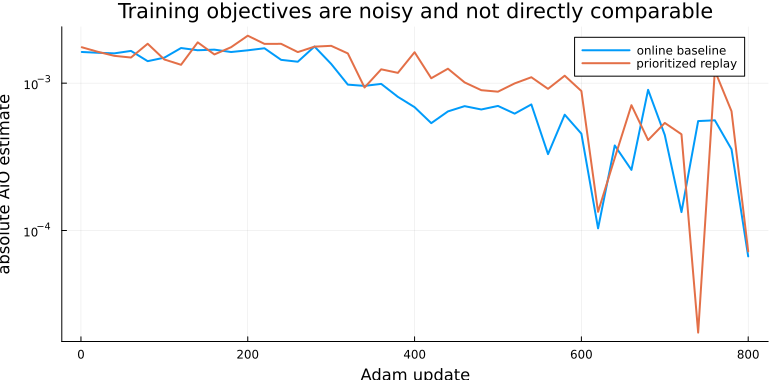

In [5]:
baseline_steps = [x.step for x in baseline.history]
priority_steps = [x.step for x in prioritized.history]
baseline_loss = abs.([x.total for x in baseline.history]) .+ 1e-12
priority_loss = abs.([x.total for x in prioritized.history]) .+ 1e-12

p_train = plot(baseline_steps, baseline_loss;
    yscale=:log10, label="online baseline",
    xlabel="Adam update", ylabel="absolute AiO estimate",
    title="Training objectives are noisy and not directly comparable")
plot!(p_train, priority_steps, priority_loss; label="prioritized replay")
p_train

## 5) Fixed, symmetric validation

Training losses use different sampling distributions, so comparing them would be misleading. Instead, we simulate fresh states from both final policies, combine them into one common feasible panel, and evaluate both networks on exactly that union with common shock seeds.

For every household-state pair, the diagnostic estimates

$$
\bar R(s,i)=\frac{1}{J}\sum_{j=1}^J R(s,i;\epsilon_j),\qquad J=24.
$$

The joint tail is defined empirically as observations above both the 90th wealth percentile and the 90th productivity percentile of the common panel.

In [6]:
baseline_panel = collect_state_panel(
    baseline.theta, par, ss; paths=5, burn=120, snapshots=10, stride=8, seed=3000)
priority_panel = collect_state_panel(
    prioritized.theta, par, ss; paths=5, burn=120, snapshots=10, stride=8, seed=3100)
common_panel = concatenate_states(baseline_panel, priority_panel)

wealth_cut = quantile(vec(common_panel.w), 0.90)
productivity_cut = quantile(vec(common_panel.y), 0.90)
@printf("common validation: %d economies x %d households\n",
    size(common_panel.w, 1), size(common_panel.w, 2))
@printf("tail thresholds: w >= %.3f and y >= %.3f\n",
    wealth_cut, productivity_cut)

baseline_errors = @time conditional_errors(
    baseline.theta, common_panel, par, ss; n_shocks=24, chunk_size=10, seed=4000)
priority_errors = @time conditional_errors(
    prioritized.theta, common_panel, par, ss; n_shocks=24, chunk_size=10, seed=4000)

baseline_summary = validation_summary(
    baseline_errors, common_panel;
    wealth_cut=wealth_cut, productivity_cut=productivity_cut)
priority_summary = validation_summary(
    priority_errors, common_panel;
    wealth_cut=wealth_cut, productivity_cut=productivity_cut)
nothing

common validation: 100 economies x 50 households
tail thresholds: w >= 12.835 and y >= 1.810
  0.773666 seconds (1.21 M allocations: 491.063 MiB, 6.49% gc time, 65.87% compilation time)
  0.260298 seconds (34.71 k allocations: 435.618 MiB, 15.06% gc time)


In [7]:
function print_metrics(label, summary)
    @printf("%-20s %8s %10s %10s %10s\n", label, "count", "median", "p90", "RMSE")
    for (name, values) in [
        ("all", summary.all),
        ("high wealth", summary.high_wealth),
        ("high productivity", summary.high_productivity),
        ("joint tail", summary.joint_tail),
    ]
        @printf("  %-18s %8d %10.4e %10.4e %10.4e\n",
            name, values.count, values.median, values.p90, values.rmse)
    end
    @printf("  mean |FB| = %.4e\n\n", summary.mean_abs_fb)
end

print_metrics("ONLINE BASELINE", baseline_summary)
print_metrics("PRIORITIZED REPLAY", priority_summary)

tail_median_change = 100 * (priority_summary.joint_tail.median / baseline_summary.joint_tail.median - 1)
all_median_change = 100 * (priority_summary.all.median / baseline_summary.all.median - 1)
@printf("median change: all states = %+.1f%%; joint tail = %+.1f%%\n",
    all_median_change, tail_median_change)

ONLINE BASELINE         count     median        p90       RMSE
  all                    5000 1.8656e-02 4.7056e-02 2.8347e-02
  high wealth             500 1.3607e-02 3.4957e-02 2.0683e-02
  high productivity       500 1.5043e-02 3.9509e-02 2.4073e-02
  joint tail              278 1.2646e-02 3.7977e-02 2.1841e-02
  mean |FB| = 2.9479e-03

PRIORITIZED REPLAY      count     median        p90       RMSE
  all                    5000 2.0554e-02 5.8236e-02 3.4501e-02
  high wealth             500 1.6457e-02 6.1178e-02 3.4215e-02
  high productivity       500 1.8700e-02 6.2240e-02 3.6027e-02
  joint tail              278 1.5233e-02 5.2567e-02 3.4558e-02
  mean |FB| = 9.6030e-03

median change: all states = +10.2%; joint tail = +20.5%


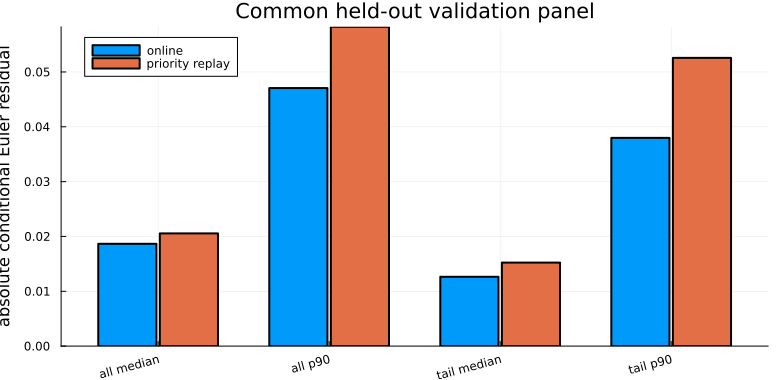

In [8]:
labels = ["all median", "all p90", "tail median", "tail p90"]
baseline_values = [
    baseline_summary.all.median, baseline_summary.all.p90,
    baseline_summary.joint_tail.median, baseline_summary.joint_tail.p90,
]
priority_values = [
    priority_summary.all.median, priority_summary.all.p90,
    priority_summary.joint_tail.median, priority_summary.joint_tail.p90,
]
x = collect(1:length(labels))
p_validation = bar(x .- 0.18, baseline_values;
    bar_width=0.34, label="online",
    ylabel="absolute conditional Euler residual",
    title="Common held-out validation panel",
    xticks=(x, labels), xrotation=15, legend=:topleft)
bar!(p_validation, x .+ 0.18, priority_values;
    bar_width=0.34, label="priority replay")
p_validation

## 6) Feasible policy slices

A rectangular $(w,y)$ grid contains impossible states. Here the horizontal grid is current assets $k$, and cash on hand is constructed as

$$
w(k,y)=(1-\delta+r_{ss})k+q_{ss}y.
$$

This guarantees $w\ge q_{ss}y$ for every plotted point.

monotonicity violations by y level: online=[0, 0, 23], replay=[0, 0, 0]


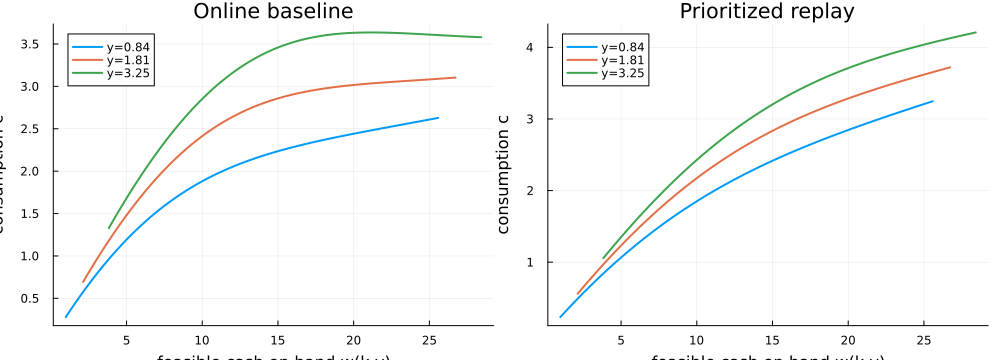

In [9]:
y_levels = quantile(vec(common_panel.y), [0.50, 0.90, 0.99])
base_state = (;
    w=copy(common_panel.w[1:1, :]),
    y=copy(common_panel.y[1:1, :]),
    z=copy(common_panel.z[1:1]),
)
baseline_slice = feasible_policy_slice(
    baseline.theta, base_state, par, ss; productivity_levels=y_levels)
priority_slice = feasible_policy_slice(
    prioritized.theta, base_state, par, ss; productivity_levels=y_levels)

p_online = plot(xlabel="feasible cash on hand w(k,y)", ylabel="consumption c",
    title="Online baseline")
p_replay = plot(xlabel="feasible cash on hand w(k,y)", ylabel="consumption c",
    title="Prioritized replay")
for j in eachindex(y_levels)
    label = "y=$(round(y_levels[j], digits=2))"
    plot!(p_online, baseline_slice.wealth[:, j], baseline_slice.consumption[:, j]; label)
    plot!(p_replay, priority_slice.wealth[:, j], priority_slice.consumption[:, j]; label)
end
@printf("monotonicity violations by y level: online=%s, replay=%s\n",
    string(baseline_slice.monotonicity_violations),
    string(priority_slice.monotonicity_violations))
plot(p_online, p_replay; layout=(1,2), size=(1000,360))

## 7) First-pilot interpretation

This pilot should be judged from the common held-out panel, not from either training-loss curve. Under the tested setting $(\lambda,\alpha,J_{priority})=(0.30,0.70,2)$, prioritized replay is **not yet an accuracy improvement**:

- all-state median conditional Euler error rises from $1.87\%$ to $2.06\%$ ($+10.2\%$);
- joint-tail median rises from $1.26\%$ to $1.52\%$ ($+20.5\%$);
- mean absolute FB residual rises from $2.95\times10^{-3}$ to $9.60\times10^{-3}$.

The feasible policy slice nevertheless improves visually: the highest-productivity curve has 23 local monotonicity violations under online training and zero under replay. This shows why policy-curve appearance alone is not a sufficient accuracy test.

The likely problem is overly aggressive and noisy prioritization: 30% of the objective is concentrated on a small set of replay households, while each stored priority uses only two future-shock draws. The next test should reduce $\lambda$, flatten sampling probabilities by reducing $\alpha$, and estimate priorities with more shocks. The present configuration should **not** yet be scaled to $(N,B,\text{steps})=(200,20,2000)$.

## 8) Conservative replay ablation

The first priority rule was intentionally strong and performed poorly on held-out Euler errors. This follow-up separates two mechanisms:

1. **uniform replay:** replace one of ten recent economies by one uniformly sampled historical economy and use all of its households;
2. **gentle priority:** keep the same 10% replay share, sample priorities with exponent $\alpha=0.35$, focus on 25 households, and estimate stored priorities with eight future shocks.

For uniform replay, every household receives exactly the same objective weight as a household in the recent sample. For gentle priority, one selected replay household receives approximately twice the weight of one recent household—far below the 6.25-fold ratio in the first pilot.

In [10]:
uniform_config = ReplayConfig(
    capacity=300, replay_fraction=0.10, priority_alpha=0.0,
    focus_agents=par.agents, refresh_every=10, priority_shocks=1,
)
gentle_config = ReplayConfig(
    capacity=300, replay_fraction=0.10, priority_alpha=0.35,
    focus_agents=25, refresh_every=10, priority_shocks=8,
)

gentle_live, gentle_buffer = prepare_initial_replay(
    theta0, par, ss; batch_size=batch_size, warmup=60, insert_every=2,
    config=gentle_config, seed=2027)
@assert gentle_live.w == initial_live.w
@printf("follow-up: uniform replay %.0f%%; gentle priority %.0f%%, alpha=%.2f, J=%d\n",
    100uniform_config.replay_fraction, 100gentle_config.replay_fraction,
    gentle_config.priority_alpha, gentle_config.priority_shocks)

follow-up: uniform replay 10%; gentle priority 10%, alpha=0.35, J=8


In [11]:
println("Training uniform replay...")
uniform_replay = @time train_prioritized_replay(
    theta0, initial_live, initial_buffer, par, ss;
    steps=steps, lr=learning_rate, seed=2030, record_every=20,
    config=uniform_config)

println("Training gentle residual-priority replay...")
gentle_replay = @time train_prioritized_replay(
    theta0, gentle_live, gentle_buffer, par, ss;
    steps=steps, lr=learning_rate, seed=2030, record_every=20,
    config=gentle_config)
nothing

Training uniform replay...
 17.104724 seconds (5.73 M allocations: 14.410 GiB, 32.56% gc time)
Training gentle residual-priority replay...
 15.685097 seconds (5.82 M allocations: 15.364 GiB, 31.35% gc time)


### What does one training batch sample?

The KS state contains an entire cross section, so this diagnostic projects each household used by the objective onto $(w_i/W_{ss},\,\log y_i/\sigma_{y,\infty})$. It shows one final training update with $B=10$ and $N=50$, rather than drawing a separate panel for every household. Blue points are recent simulated households. Orange points are historical households that enter through replay. In the gentle-priority panel, gray open circles show the rest of the sampled historical economy for context; only the highlighted orange households receive replay weight. Marker size records repeated priority draws.

In [ ]:
sampling_rng = MersenneTwister(731)
stationary_y_sd = par.sigma_y / sqrt(1 - par.rho_y^2)

function sampling_rows(state, rows, rng)
    selected_rows = randperm(rng, size(state.w, 1))[1:rows]
    return (;
        w=copy(state.w[selected_rows, :]),
        y=copy(state.y[selected_rows, :]),
        z=copy(state.z[selected_rows]),
    )
end

sampling_coordinates(state) = (
    vec(state.w ./ ss.W),
    vec(log.(max.(state.y, 1e-12)) ./ stationary_y_sd),
)

# One B=10 update: online uses 10 recent economies; replay uses 9 recent + 1 historical.
online_recent = baseline.live
uniform_recent = sampling_rows(uniform_replay.live, 9, sampling_rng)
gentle_recent = sampling_rows(gentle_replay.live, 9, sampling_rng)
uniform_history, _, _ = KSReplayExperiment.sample_replay(
    uniform_replay.buffer, sampling_rng, 1, par.agents; alpha=0.0)
gentle_history, gentle_focus, _ = KSReplayExperiment.sample_replay(
    gentle_replay.buffer, sampling_rng, 1, gentle_config.focus_agents;
    alpha=gentle_config.priority_alpha)

online_x, online_y = sampling_coordinates(online_recent)
uniform_recent_x, uniform_recent_y = sampling_coordinates(uniform_recent)
uniform_history_x, uniform_history_y = sampling_coordinates(uniform_history)
gentle_recent_x, gentle_recent_y = sampling_coordinates(gentle_recent)
gentle_history_x, gentle_history_y = sampling_coordinates(gentle_history)

gentle_draws = vec(gentle_focus)
gentle_counts = [count(==(i), gentle_draws) for i in 1:par.agents]
gentle_selected = findall(>(0), gentle_counts)
gentle_selected_sizes = 4 .+ 2 .* sqrt.(gentle_counts[gentle_selected])

recent_color = "#4C78A8"
replay_color = "#F28E2B"
context_color = "#9AA0A6"
common_sampling_style = (
    xlims=(0.0, par.wealth_scale_multiple), ylims=(-2.05, 2.05),
    xlabel="w / W_ss", ylabel="log(y) / stationary sd(y)",
    legend=:topleft, legendfontsize=7, gridalpha=0.18,
)

p_online_sampling = scatter(online_x, online_y;
    common_sampling_style..., title="Online simulation",
    color=recent_color, markersize=3, markeralpha=0.55,
    markerstrokewidth=0, label="recent simulation")

p_uniform_sampling = scatter(uniform_recent_x, uniform_recent_y;
    common_sampling_style..., title="Uniform 10% replay",
    color=recent_color, markersize=3, markeralpha=0.45,
    markerstrokewidth=0, label="recent simulation")
scatter!(p_uniform_sampling, uniform_history_x, uniform_history_y;
    marker=:circle, markercolor=:white, markerstrokecolor=replay_color,
    markerstrokewidth=1.2, markersize=4, label="uniform replay")

p_gentle_sampling = scatter(gentle_recent_x, gentle_recent_y;
    common_sampling_style..., title="Gentle priority 10% replay",
    color=recent_color, markersize=3, markeralpha=0.45,
    markerstrokewidth=0, label="recent simulation")
scatter!(p_gentle_sampling, gentle_history_x, gentle_history_y;
    marker=:circle, markercolor=:white, markerstrokecolor=context_color,
    markerstrokewidth=0.8, markersize=3.5, label="replay economy")
scatter!(p_gentle_sampling,
    gentle_history_x[gentle_selected], gentle_history_y[gentle_selected];
    marker=:diamond, color=replay_color, markersize=gentle_selected_sizes,
    markerstrokewidth=0, label="priority-selected")

sampling_figure = plot(
    p_online_sampling, p_uniform_sampling, p_gentle_sampling;
    layout=(1, 3), link=:both, size=(1350, 390))

### Common follow-up validation panel

The online, uniform-replay, and gentle-priority policies are evaluated on the union of fresh states generated by all three final policies. Tail thresholds and common shocks are recomputed from this symmetric panel.

In [12]:
uniform_panel = collect_state_panel(
    uniform_replay.theta, par, ss; paths=5, burn=120, snapshots=10, stride=8, seed=3200)
gentle_panel = collect_state_panel(
    gentle_replay.theta, par, ss; paths=5, burn=120, snapshots=10, stride=8, seed=3300)
ablation_panel = concatenate_states(baseline_panel, uniform_panel, gentle_panel)

ablation_w_cut = quantile(vec(ablation_panel.w), 0.90)
ablation_y_cut = quantile(vec(ablation_panel.y), 0.90)
@printf("follow-up validation: %d economies x %d households; w tail %.3f, y tail %.3f\n",
    size(ablation_panel.w,1), size(ablation_panel.w,2),
    ablation_w_cut, ablation_y_cut)

online2_errors = conditional_errors(
    baseline.theta, ablation_panel, par, ss; n_shocks=24, chunk_size=10, seed=4100)
uniform_errors = conditional_errors(
    uniform_replay.theta, ablation_panel, par, ss; n_shocks=24, chunk_size=10, seed=4100)
gentle_errors = conditional_errors(
    gentle_replay.theta, ablation_panel, par, ss; n_shocks=24, chunk_size=10, seed=4100)

online2_summary = validation_summary(online2_errors, ablation_panel;
    wealth_cut=ablation_w_cut, productivity_cut=ablation_y_cut)
uniform_summary = validation_summary(uniform_errors, ablation_panel;
    wealth_cut=ablation_w_cut, productivity_cut=ablation_y_cut)
gentle_summary = validation_summary(gentle_errors, ablation_panel;
    wealth_cut=ablation_w_cut, productivity_cut=ablation_y_cut)
nothing

follow-up validation: 150 economies x 50 households; w tail 12.894, y tail 1.797


In [13]:
print_metrics("ONLINE BASELINE", online2_summary)
print_metrics("UNIFORM REPLAY", uniform_summary)
print_metrics("GENTLE PRIORITY", gentle_summary)

for (label, summary) in [("uniform", uniform_summary), ("gentle", gentle_summary)]
    all_change = 100(summary.all.median / online2_summary.all.median - 1)
    tail_change = 100(summary.joint_tail.median / online2_summary.joint_tail.median - 1)
    @printf("%-8s median change: all=%+.1f%%, joint tail=%+.1f%%\n",
        label, all_change, tail_change)
end

ONLINE BASELINE         count     median        p90       RMSE
  all                    7500 1.9329e-02 4.8715e-02 2.9435e-02
  high wealth             750 1.3740e-02 3.2711e-02 2.0149e-02
  high productivity       750 1.5855e-02 3.9543e-02 2.4663e-02
  joint tail              347 1.4569e-02 3.6852e-02 2.2434e-02
  mean |FB| = 2.8051e-03

UNIFORM REPLAY          count     median        p90       RMSE
  all                    7500 2.0036e-02 5.1904e-02 3.1293e-02
  high wealth             750 1.4433e-02 3.4563e-02 2.1060e-02
  high productivity       750 1.6365e-02 4.4832e-02 2.7455e-02
  joint tail              347 1.2859e-02 3.8355e-02 2.1640e-02
  mean |FB| = 6.1285e-03

GENTLE PRIORITY         count     median        p90       RMSE
  all                    7500 1.9274e-02 4.7966e-02 2.9338e-02
  high wealth             750 1.4183e-02 3.7241e-02 2.2544e-02
  high productivity       750 1.5956e-02 4.4022e-02 2.6769e-02
  joint tail              347 1.3226e-02 4.2706e-02 2.3514e-02
  m

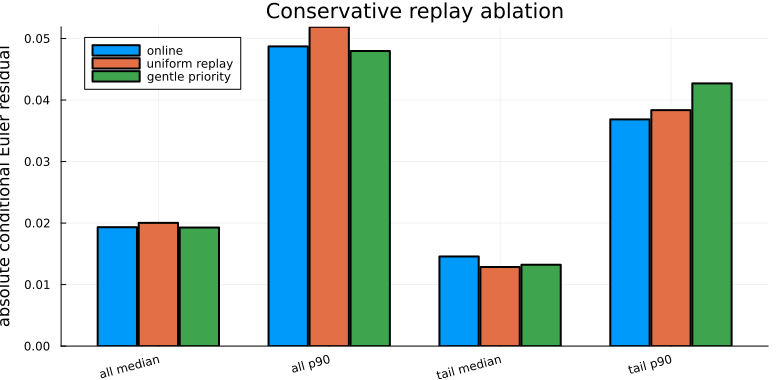

In [14]:
follow_labels = ["all median", "all p90", "tail median", "tail p90"]
metric_vector(s) = [s.all.median, s.all.p90, s.joint_tail.median, s.joint_tail.p90]
online_values = metric_vector(online2_summary)
uniform_values = metric_vector(uniform_summary)
gentle_values = metric_vector(gentle_summary)
x = collect(1:length(follow_labels))
p_follow = bar(x .- 0.24, online_values; bar_width=0.23, label="online",
    ylabel="absolute conditional Euler residual",
    title="Conservative replay ablation",
    xticks=(x,follow_labels), xrotation=15, legend=:topleft)
bar!(p_follow, x, uniform_values; bar_width=0.23, label="uniform replay")
bar!(p_follow, x .+ 0.24, gentle_values; bar_width=0.23, label="gentle priority")
p_follow

monotonicity violations: online=[0, 0, 23], uniform=[0, 0, 18], gentle=[0, 0, 0]


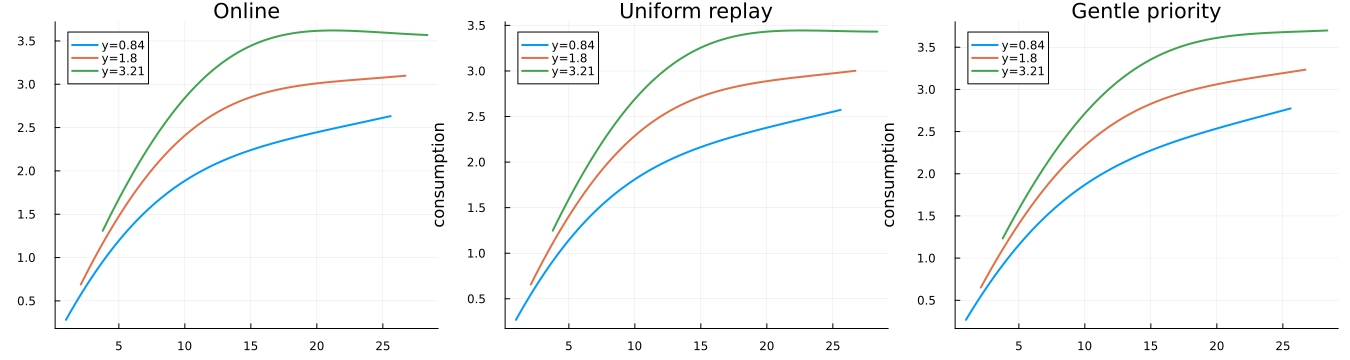

In [15]:
follow_y = quantile(vec(ablation_panel.y), [0.50,0.90,0.99])
follow_base = (; w=copy(ablation_panel.w[1:1,:]),
    y=copy(ablation_panel.y[1:1,:]), z=copy(ablation_panel.z[1:1]))
online_slice2 = feasible_policy_slice(
    baseline.theta, follow_base, par, ss; productivity_levels=follow_y)
uniform_slice = feasible_policy_slice(
    uniform_replay.theta, follow_base, par, ss; productivity_levels=follow_y)
gentle_slice = feasible_policy_slice(
    gentle_replay.theta, follow_base, par, ss; productivity_levels=follow_y)

plots = [plot(xlabel="feasible cash on hand", ylabel="consumption", title=t)
    for t in ["Online","Uniform replay","Gentle priority"]]
for (panel, slice) in zip(plots, [online_slice2,uniform_slice,gentle_slice])
    for j in eachindex(follow_y)
        plot!(panel, slice.wealth[:,j], slice.consumption[:,j];
            label="y=$(round(follow_y[j],digits=2))")
    end
end
@printf("monotonicity violations: online=%s, uniform=%s, gentle=%s\n",
    string(online_slice2.monotonicity_violations),
    string(uniform_slice.monotonicity_violations),
    string(gentle_slice.monotonicity_violations))
plot(plots...; layout=(1,3), size=(1350,360))

## 9) Gentle-priority policy rules on the original rectangular grid

For direct comparison with the main notebook, this figure uses the same common grid for every productivity level,

$$
w\in[0.05W_{ss},4W_{ss}],\qquad \log y\in[-2\sigma_{y,\infty},2\sigma_{y,\infty}].
$$

Unlike the feasible-support figure above, this rectangular diagnostic also includes rare or off-support $(w,y)$ combinations. It is useful for seeing the global shape of the learned policy, but held-out Euler and KKT residuals remain the accuracy criteria.

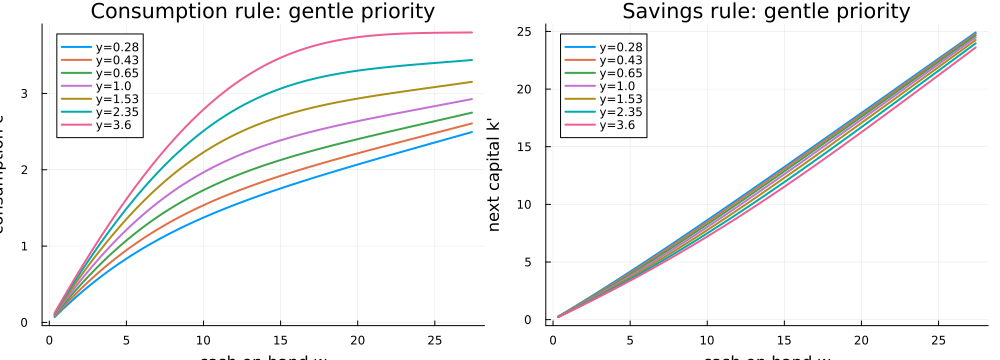

In [16]:
gentle_rectangular = rectangular_policy_slice(
    gentle_replay.theta, follow_base, par, ss;
    agent=1, points=100, productivity_points=7)

p_consumption = plot(
    xlabel="cash on hand w", ylabel="consumption c",
    title="Consumption rule: gentle priority")
p_savings = plot(
    xlabel="cash on hand w", ylabel="next capital k'",
    title="Savings rule: gentle priority")
for j in eachindex(gentle_rectangular.productivity_grid)
    label = "y=$(round(gentle_rectangular.productivity_grid[j], digits=2))"
    plot!(p_consumption, gentle_rectangular.wealth_grid,
        gentle_rectangular.consumption[:, j]; lw=2, label=label)
    plot!(p_savings, gentle_rectangular.wealth_grid,
        gentle_rectangular.savings[:, j]; lw=2, label=label)
end
plot(p_consumption, p_savings; layout=(1,2), size=(1000,360))

## 10) Follow-up interpretation

The conservative designs improve some tail diagnostics, but neither dominates the online baseline. Relative to online training:

- **Uniform 10% replay:** the joint-tail median Euler error falls by **11.7%**, but the all-state median rises by **3.7%**, the joint-tail p90 rises by about **4.1%**, and mean absolute FB residual more than doubles.
- **Gentle priority replay:** the all-state median is essentially unchanged (**-0.3%**) and the joint-tail median falls by **9.2%**. However, the joint-tail p90 rises by about **15.9%**, and mean absolute FB residual again more than doubles.
- The feasible policy slice becomes smoother: the highest-productivity curve has 23 monotonicity violations online, 18 with uniform replay, and 0 with gentle priority. This visual improvement is not sufficient evidence of a more accurate solution.

The experiment therefore identifies a real coverage effect, but also a trade-off. Replay gives rare states more gradient weight and improves the typical joint-tail observation, while the current reweighting worsens the hardest tail observations and complementarity accuracy. The likely issue is not replay alone: noisy per-household priorities and the changed relative weighting of Euler and KKT residuals alter the optimization target.

**Decision:** do not replace the main notebook's online sampler with either experimental rule. A next version should keep a fixed natural validation set, normalize the Euler and KKT objectives separately, and confirm any improvement across several training seeds before adoption.